# Week 11: Regression discontinuity designs
**DS-UA 201 · Fall 2026**  
**Center for Data Science, New York University**  

**TA: Xiang Gao**

Nov 20, 2026

[Open in Colab](https://colab.research.google.com/github/xgao0o/DS-UA_201-Causal-Inference-Fall-2026/blob/main/labs/11-RDD.ipynb) (available after publication to the repository).

## Setup
Run cells from top to bottom, or choose **Restart Kernel and Run All Cells**. We use NumPy, pandas, Matplotlib, and statsmodels.

- **Locally:** keep this notebook in `labs/` and the accompanying [lee_data.csv](../data/lee_data.csv) and [drinking.csv](../data/drinking.csv) in `data/`. The loader works from the repository root or `labs/`.
- **Colab:** upload the notebook and both CSV files using the Files sidebar. A new session may require uploading them again.
- If needed, install with `python -m pip install numpy pandas matplotlib statsmodels` (or `%pip install numpy pandas matplotlib statsmodels` in a Colab cell).

See the [course README](../README.md) for Jupyter setup. Installation is a setup step; the analysis cells do not install packages or fetch data.

In [1]:
%matplotlib inline

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (7, 4), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREEN = "#526F8A", "#B85C38", "#477766"

def read_lab_csv(filename):
    candidates = [Path("data") / filename, Path("../data") / filename,
                  Path(filename)]
    for path in candidates:
        if path.is_file():
            return pd.read_csv(path)
    raise FileNotFoundError(
        f"Upload {filename} in Colab, or keep it in the repository's data/ folder."
    )

## 1. Sharp RDD: a rule creates a cutoff
A **running variable** (also called a score or forcing variable), $R_i$, determines eligibility through a known **cutoff**, $c$:

$$Z_i=\mathbf{1}\{R_i\geq c\}.$$

We use $Z_i$ for assignment or eligibility and $S_i$ for treatment actually received. In a **sharp RDD**, everyone follows the rule, so $S_i=Z_i$. In a **fuzzy RDD**, treatment receipt is imperfect, but its probability jumps at the cutoff.

| Setting | Running variable | Cutoff | Treatment or assignment |
|:--|:--|:--|:--|
| Election | Candidate's vote margin over strongest opponent | 0 | Winning the election |
| Drinking-age example | Age | 21 | Legal access to alcohol |
| University example | Entrance score | 1200 (hypothetical) | Admission eligibility; enrollment may differ |

Define $Y_i(1)$ and $Y_i(0)$ as the outcomes under treatment and no treatment. With a well-defined treatment, no interference, and consistency,

$$Y_i=S_iY_i(1)+(1-S_i)Y_i(0).$$

Scores can predict outcomes even without treatment. RDD asks whether the outcome has a **jump at the policy cutoff**, beyond the relationship with the score.

### Parameter → identification → estimator → estimate
The sharp-RDD **causal parameter** is an average treatment effect at the cutoff:

$$\tau_{\mathrm{SRD}}(c)=\mathbb E[Y(1)-Y(0)\mid R=c].$$

Let $\mu_s(r)=\mathbb E[Y(s)\mid R=r]$. **Identification** requires both $\mu_0(r)$ and $\mu_1(r)$ to be continuous at $c$, with observations arbitrarily close on both sides. Then

$$\begin{aligned}
\Delta_Y(c)
&=\lim_{r\to c^+}\mathbb E[Y\mid R=r]
 -\lim_{r\to c^-}\mathbb E[Y\mid R=r]\\
&=\mu_1(c)-\mu_0(c)=\tau_{\mathrm{SRD}}(c).
\end{aligned}$$

Here $c^+$ means approaching **from above**, and $c^-$ means approaching **from below**. For a continuous score, the conditional expectations at $c$ are interpreted through these smooth limits; we do not need observations exactly at $c$.

An **estimator** uses data to estimate the two limits; its numerical value in our dataset is an **estimate**. We will use local linear regression.

**What continuity does and does not say.** Individuals need not have identical outcomes, and $R$ may affect outcomes smoothly. Assignment is deterministic given $R$; it is not literally randomized. An assumption of random assignment within a finite window is a separate, stronger approach. The effect at $c$ need not equal the population ATE or the average effect across everyone in our chosen window.

Substantive threats include precise sorting around the threshold, changes in who is observed, and another intervention starting at exactly the same cutoff. A jump alone does not establish causality.

### Exercise 1: what is sharp?
At age 21, legal access changes, but some people drink before 21 and others never drink. Is this a sharp RDD for legal access? For actual drinking? What must be continuous?

<details><summary>Answer</summary>
<p>In the study's threshold setup, legal access is assigned sharply by age. Actual drinking is not: a consumption effect would require a fuzzy design and a measured jump in consumption. For the sharp access effect, expected potential mortality under each access status must be continuous in age at 21. Observed mortality is allowed to jump because access changes. Other causes of mortality can vary smoothly with age.</p>
</details>

## 2. Elections: assignment and design diagnostics
We use the election data associated with [Lee's incumbency study](https://doi.org/10.1016/j.jeconom.2007.05.004). The causal question is whether narrowly winning an election improves **subsequent** electoral success.

A row describes a candidate in an election. We select Democratic candidates so the diagnostic plots do not mechanically include both sides of the same race.

| Column | Use here |
|:--|:--|
| `origvote`, `totvote` | Candidate votes and total votes |
| `highestvote`, `sechighestvote` | Largest and second-largest vote totals |
| `partname` | Party label; we keep `D` |
| `officeexp` | Recorded prior office-holding experience; a baseline characteristic |

**Use the actual assignment rule.** A candidate can win a plurality with less than 50% of total votes. Define the running variable as

$$R_i=100\frac{\text{candidate votes}-\text{strongest opponent's votes}}{\text{total votes}}.$$

The units are **percentage points of total votes**, and the cutoff is 0. For a winner, the strongest opponent has the second-highest total; for a loser, the strongest opponent has the highest total. We omit rows lacking a second-highest total and check for ties.

In [2]:
elections_raw = read_lab_csv("lee_data.csv")
elections = elections_raw.loc[
    elections_raw["partname"].eq("D")
    & elections_raw["sechighestvote"].notna()
    & elections_raw["totvote"].gt(0)
].copy()

assert not elections["highestvote"].eq(elections["sechighestvote"]).any()
elections["won"] = elections["origvote"].eq(elections["highestvote"]).astype(int)
opponent_votes = np.where(
    elections["won"].eq(1), elections["sechighestvote"], elections["highestvote"]
)
elections["margin"] = 100 * (elections["origvote"] - opponent_votes) / elections["totvote"]
assert np.array_equal(elections["won"], (elections["margin"] >= 0).astype(int))

print(f"Original candidate rows: {len(elections_raw):,}; retained Democratic rows: {len(elections):,}")
print("Retained winners with less than 50% of total votes:",
      ((elections["won"] == 1) & (elections["origvote"] / elections["totvote"] < 0.5)).sum())
display(elections[["yearel", "margin", "won", "officeexp"]].head().round(3))

Original candidate rows: 19,857; retained Democratic rows: 9,202
Retained winners with less than 50% of total votes: 249


,yearel,margin,won,officeexp
0,1946,-6.149,0,0
2,1948,10.487,1,0
4,1950,16.446,1,1
6,1952,7.936,1,0
8,1954,13.925,1,1


### Look for discontinuities, not global independence
1. Plot the **distribution of the running variable** near zero. Unusual bunching can raise concerns about sorting or recording rules.
2. Plot a **pretreatment characteristic** against the running variable. It can trend with the margin; the question is whether it jumps at zero.

Binned means make the plot readable. Our bins meet at the cutoff, so no bin mixes winners and losers. The horizontal coordinate is the observed mean margin within each bin. Bin width is a plotting choice, distinct from the estimation bandwidth introduced below.

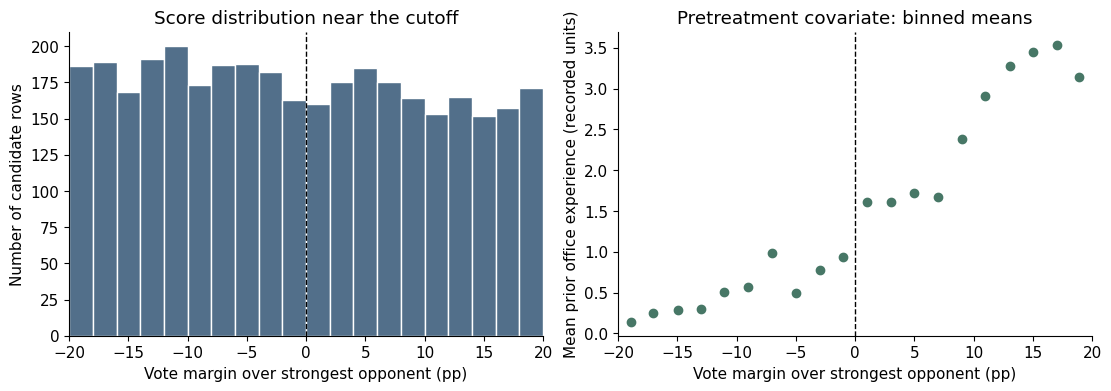

In [3]:
def binned_means(data, running, outcome, edges):
    view = data[[running, outcome]].dropna().copy()
    view["bin"] = pd.cut(view[running], bins=edges, right=False)
    return (view.groupby("bin", observed=True)
            .agg(r=(running, "mean"), y=(outcome, "mean"), n=(outcome, "size"))
            .reset_index(drop=True))

election_bins = np.linspace(-20, 20, 21)  # 2 percentage points per bin; 0 is an edge
experience_bins = binned_means(elections, "margin", "officeexp", election_bins)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
axes[0].hist(elections["margin"], bins=election_bins, color=BLUE, edgecolor="white")
axes[0].set(ylabel="Number of candidate rows", title="Score distribution near the cutoff")
axes[1].scatter(experience_bins["r"], experience_bins["y"], color=GREEN)
axes[1].set(ylabel="Mean prior office experience (recorded units)",
            title="Pretreatment covariate: binned means")
for ax in axes:
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel="Vote margin over strongest opponent (pp)", xlim=(-20, 20))
plt.show()

**Reading this plot:** the nearest plotted experience bins on the two sides do not line up exactly. This is a reason to investigate the sample and the behavior closer to zero, rather than simply assume baseline balance. Coarse bins, sampling variation, and the simplified sample matter.

### Exercise 2: diagnose carefully
1. Would a smooth-looking covariate plot prove that unobserved potential outcomes are continuous?
2. Is a histogram a formal test for manipulation? Why use only one party here?

<details><summary>Answers</summary>
<ol>
<li>No. Baseline covariates provide indirect evidence. A jump is a reason to investigate the design; the absence of a visible jump does not establish continuity of unobserved potential outcomes.</li>
<li>No. Counts depend on bin width, sampling noise, and the selected sample. Formal density procedures require additional work. Pooling both candidates from two-candidate races creates paired, opposite margins, which can mechanically make the density look symmetric. Restricting to one party avoids that particular problem but does not establish validity.</li>
</ol>
<p>The experience plot can trend across the score range without invalidating RDD. Examine its behavior near zero, and do not interpret a coarse visual pattern as a definitive balance test.</p>
</details>

## 3. Drinking age: local linear estimation
We now use `drinking.csv`, an age-aggregated teaching extract associated with [Carpenter and Dobkin (2009)](https://www.aeaweb.org/articles?id=10.1257/app.1.1.164).

The running variable is age and the cutoff is 21. For this sharp analysis, **the treatment is legal access to alcohol**, not whether an individual drinks. The outcome is a mortality rate. A causal interpretation requires potential mortality rates to change continuously through age 21 absent the access change, with no other discontinuous cause at that age.

| Column | Meaning |
|:--|:--|
| `agecell` | Age location of an aggregated cell, in years |
| `all` | All-cause mortality rate |
| `mva` | Motor-vehicle mortality rate |
| `suicide` | Suicide mortality rate |

Rates are deaths per 100,000 person-years. A row is an **age cell**, not a person. Two rows have fitted values but no observed mortality rates; we exclude them. We never treat the supplied `*fitted` columns as observed outcomes. These classroom fits are not a replication of the paper's full analysis.

In [4]:
drinking_raw = read_lab_csv("drinking.csv")
drinking = (drinking_raw[["agecell", "all", "mva", "suicide"]]
            .dropna().sort_values("agecell").copy())
drinking["x"] = drinking["agecell"] - 21
drinking["Z"] = (drinking["x"] >= 0).astype(int)
print(f"Observed age cells: {len(drinking)}; excluded rows: {len(drinking_raw) - len(drinking)}")
display(drinking.head().round(3))

Observed age cells: 48; excluded rows: 2


,agecell,all,mva,suicide,x,Z
0,19.068,92.825,35.829,11.204,-1.932,0
1,19.151,95.101,35.639,12.193,-1.849,0
2,19.233,92.144,34.206,11.716,-1.767,0
3,19.315,88.428,32.279,11.275,-1.685,0
4,19.397,88.705,32.651,10.984,-1.603,0


### Estimate the limits with separate lines
Center the score: $x_i=R_i-c$. Within a bandwidth $h$, use the local approximation

$$Y_i\approx\alpha+\tau Z_i+\beta x_i+\gamma Z_i x_i,\qquad |x_i|<h.$$

- **Below the cutoff:** fitted line $\widehat\alpha+\widehat\beta x$.
- **Above the cutoff:** fitted line $(\widehat\alpha+\widehat\tau)+(\widehat\beta+\widehat\gamma)x$.
- **Estimated jump at $x=0$:** $\widehat\tau$, the gap between the fitted intercepts.

The interaction permits different slopes. Centering makes the coefficient on $Z$ the intercept gap **at the cutoff**. This is an effect of the treatment under identification assumptions, not a causal effect of the running variable itself.

The local linear specification approximates the conditional means. Continuity does not make them exactly linear over a finite window. Thus $\widehat\tau$ can have approximation bias as well as sampling error.

In [5]:
def rd_design(x):
    """Columns for separate intercepts and slopes, centered at the cutoff."""
    x = np.asarray(x, dtype=float)
    z = (x >= 0).astype(float)
    return pd.DataFrame({"const": np.ones(len(x)), "Z": z, "x": x, "Z_x": z * x})

def fit_local_linear(data, outcome, running, cutoff, h, kernel="uniform"):
    """Estimate a cutoff jump on complete rows with |R-c| < h."""
    if h <= 0 or kernel not in ("uniform", "triangular"):
        raise ValueError("Use h > 0 and kernel='uniform' or 'triangular'.")
    sample = data[[running, outcome]].dropna().copy()
    sample["x"] = sample[running] - cutoff
    sample = sample.loc[sample["x"].abs() < h].reset_index(drop=True)
    x = sample["x"].to_numpy()
    X = rd_design(x)
    if (x < 0).sum() < 3 or (x >= 0).sum() < 3 or np.linalg.matrix_rank(X) < 4:
        raise ValueError("The bandwidth needs more distinct observations on both sides.")
    weights = np.ones(len(x)) if kernel == "uniform" else 1 - np.abs(x) / h
    fit = sm.WLS(sample[outcome], X, weights=weights).fit()
    return {"fit": fit, "sample": sample, "weights": weights,
            "h": h, "cutoff": cutoff, "kernel": kernel}

sharp_fit = fit_local_linear(drinking, "all", "agecell", cutoff=21, h=1)
display(sharp_fit["fit"].params.rename("Estimated coefficient").to_frame().round(3))

,Estimated coefficient
const,92.524
Z,9.753
x,-1.612
Z_x,-3.289


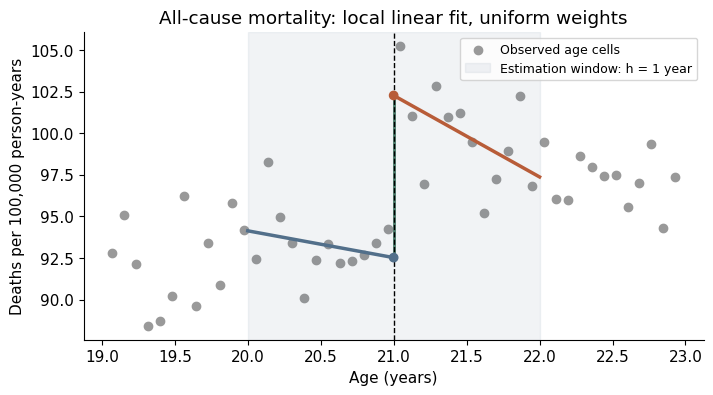

Estimated left limit: 92.52
Estimated right limit: 102.28
Estimated jump: 9.75 deaths per 100,000 person-years
Jump relative to fitted left limit: 10.54%


In [6]:
def draw_rd_lines(ax, result):
    """Draw each fitted line only on its own side and within the bandwidth."""
    h, cutoff = result["h"], result["cutoff"]
    a, tau, b, g = result["fit"].params[["const", "Z", "x", "Z_x"]]
    for z, color in [(0, BLUE), (1, ORANGE)]:
        grid = np.linspace(-h, 0, 100) if z == 0 else np.linspace(0, h, 100)
        prediction = a + tau * z + (b + g * z) * grid
        ax.plot(grid + cutoff, prediction, color=color, linewidth=2.5)
    ax.plot([cutoff, cutoff], [a, a + tau], color=GREEN, linewidth=2)
    ax.scatter([cutoff, cutoff], [a, a + tau], color=[BLUE, ORANGE], zorder=5)
    ax.axvline(cutoff, color="black", linestyle="--", linewidth=1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(drinking["agecell"], drinking["all"], color="0.6", label="Observed age cells")
ax.axvspan(20, 22, color=BLUE, alpha=0.08, label="Estimation window: h = 1 year")
draw_rd_lines(ax, sharp_fit)
ax.set(xlabel="Age (years)", ylabel="Deaths per 100,000 person-years",
       title="All-cause mortality: local linear fit, uniform weights")
ax.legend(fontsize=9)
plt.show()

left_limit = sharp_fit["fit"].params["const"]
jump = sharp_fit["fit"].params["Z"]
print(f"Estimated left limit: {left_limit:.2f}")
print(f"Estimated right limit: {left_limit + jump:.2f}")
print(f"Estimated jump: {jump:.2f} deaths per 100,000 person-years")
print(f"Jump relative to fitted left limit: {100 * jump / left_limit:.2f}%")

### Exercise 3: interpret the coefficient
Suppose the fitted left limit were 93 and the right limit 101 deaths per 100,000 person-years.

1. What are the estimated jump and its percentage change relative to the left limit?
2. Does this estimate the effect of drinking one more drink? Does it identify the effect of changing the cutoff from 21 to 18?

<details><summary>Answer and Python</summary>
<p>The jump is 8 deaths per 100,000 person-years, and the relative change is about 8.60%. This is not an 8-percentage-point change in an individual's death probability. Under the sharp-RDD assumptions, it estimates an effect of legal access at age 21. It does not identify an effect per drink or an effect at age 18 without additional data and assumptions.</p>
<pre><code>left, right = 93, 101
jump = right - left
percent_change = 100 * jump / left
print(jump, percent_change)</code></pre>
</details>

## 4. Bandwidths and kernel weights
The **bandwidth** $h$ determines how far from the cutoff observations may contribute. A smaller $h$ usually reduces approximation bias but leaves fewer observations and more sampling variability; a larger $h$ adds information but may fit poorly at the boundary. This is a tradeoff, not a guarantee that estimates move monotonically with $h$.

A **kernel** determines weights within the window. For the centered score $x$:

$$w_{\mathrm{uniform}}(x)=\mathbf{1}\{|x|<h\},\qquad
w_{\mathrm{triangular}}(x)=\mathbf{1}\{|x|<h\}\left(1-\frac{|x|}{h}\right).$$

Weighted least squares minimizes $\sum_i w_i(Y_i-\alpha-\tau Z_i-\beta x_i-\gamma Z_i x_i)^2$. Triangular weights emphasize observations close to the cutoff. They are distance weights, not population counts or inverse-variance weights; multiplying all weights by the same positive constant leaves the point estimate unchanged.

We chose the bandwidth grid below for teaching, before comparing estimates. Do not select a window because it produces a preferred sign or p-value.

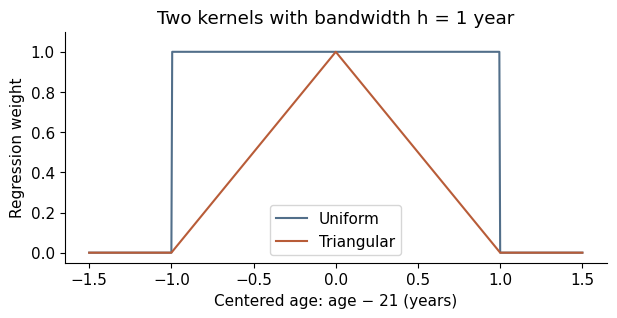

,h (years),kernel,left cells,right cells,jump (rate units)
0,0.50,uniform,6,6,8.878
1,0.50,triangular,6,6,9.567
2,0.75,uniform,9,9,9.848
3,0.75,triangular,9,9,9.460
4,1.00,uniform,12,12,9.753
5,1.00,triangular,12,12,9.700
6,1.50,uniform,18,18,8.700
7,1.50,triangular,18,18,9.287
8,2.00,uniform,24,24,7.663
9,2.00,triangular,24,24,8.381


In [7]:
x_grid = np.linspace(-1.5, 1.5, 601)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x_grid, (np.abs(x_grid) < 1).astype(float), label="Uniform", color=BLUE)
ax.plot(x_grid, np.maximum(1 - np.abs(x_grid), 0), label="Triangular", color=ORANGE)
ax.set(xlabel="Centered age: age − 21 (years)", ylabel="Regression weight",
       title="Two kernels with bandwidth h = 1 year", ylim=(-0.05, 1.1))
ax.legend()
plt.show()

rows = []
for h in [0.5, 0.75, 1.0, 1.5, 2.0]:
    for kernel in ["uniform", "triangular"]:
        result = fit_local_linear(drinking, "all", "agecell", 21, h, kernel)
        x = result["sample"]["x"]
        rows.append({"h (years)": h, "kernel": kernel,
                     "left cells": int((x < 0).sum()), "right cells": int((x >= 0).sum()),
                     "jump (rate units)": result["fit"].params["Z"]})
bandwidth_results = pd.DataFrame(rows)
display(bandwidth_results.round(3))

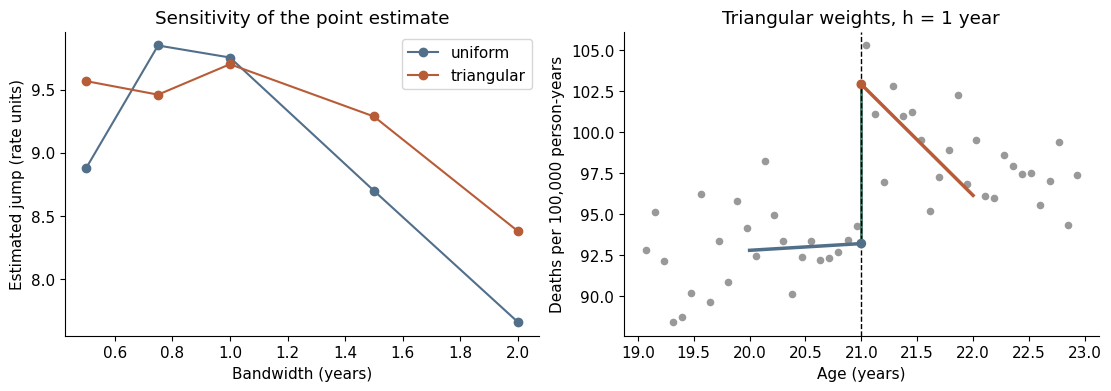

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for kernel, color in [("uniform", BLUE), ("triangular", ORANGE)]:
    subset = bandwidth_results.loc[bandwidth_results["kernel"].eq(kernel)]
    axes[0].plot(subset["h (years)"], subset["jump (rate units)"], "o-",
                 color=color, label=kernel)
axes[0].set(xlabel="Bandwidth (years)", ylabel="Estimated jump (rate units)",
            title="Sensitivity of the point estimate")
axes[0].legend()
triangular_fit = fit_local_linear(drinking, "all", "agecell", 21, h=1, kernel="triangular")
axes[1].scatter(drinking["agecell"], drinking["all"], color="0.6", s=20)
draw_rd_lines(axes[1], triangular_fit)
axes[1].set(xlabel="Age (years)", ylabel="Deaths per 100,000 person-years",
            title="Triangular weights, h = 1 year")
plt.show()

Plot all-cause, motor-vehicle, and suicide mortality. Repeat the same local fit for each, using triangular weights and a bandwidth of one year. Outcomes have different scales, so each panel has its own vertical axis

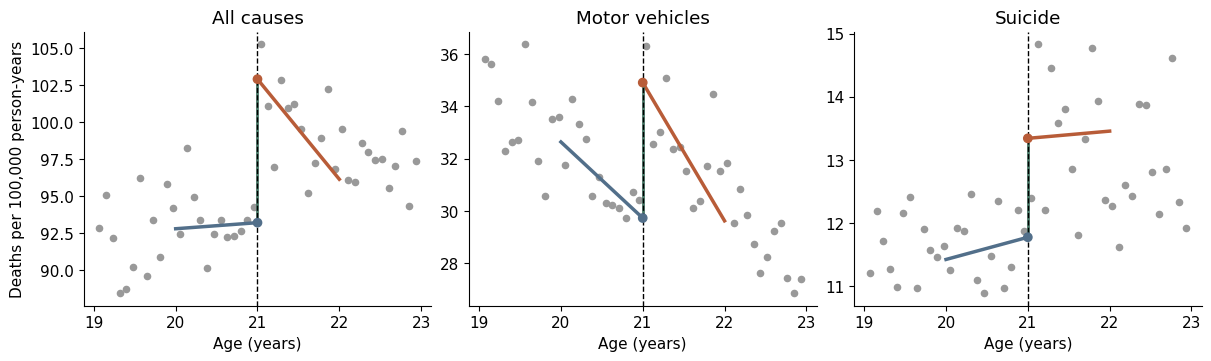

,Outcome,Left limit,Jump,Relative change (%)
0,All causes,93.200,9.700,10.408
1,Motor vehicles,29.733,5.181,17.426
2,Suicide,11.776,1.565,13.291


In [12]:
cause_labels = {"all": "All causes", "mva": "Motor vehicles", "suicide": "Suicide"}
cause_results = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, (outcome, label) in zip(axes, cause_labels.items()):
    result = fit_local_linear(drinking, outcome, "agecell", 21, 1, "triangular")
    left = result["fit"].params["const"]
    jump = result["fit"].params["Z"]
    cause_results.append({"Outcome": label, "Left limit": left, "Jump": jump,
                          "Relative change (%)": 100 * jump / left})
    ax.scatter(drinking["agecell"], drinking[outcome], color="0.6", s=20)
    draw_rd_lines(ax, result)
    ax.set(xlabel="Age (years)", title=label)
axes[0].set_ylabel("Deaths per 100,000 person-years")
plt.show()
display(pd.DataFrame(cause_results).round(3))

### What about uncertainty?
These are **point estimates** from aggregated age cells. The spread across bandwidths is a sensitivity check, not a confidence interval. Each row contains many people, and this file does not supply the original individual records or age-cell exposure counts.

Even with individual data, ordinary regression standard errors, including heteroskedasticity-robust standard errors, do not automatically account for local approximation bias. A formal RD analysis needs suitable bandwidth selection, bias-aware inference, and the correct sampling or dependence structure. [Cattaneo, Idrobo, and Titiunik's guide](https://mdcattaneo.github.io/books/Cattaneo-Idrobo-Titiunik_2020_CUP.pdf) explains robust bias-corrected inference; the authors' [rdrobust package](https://github.com/rdpackages/rdrobust) implements it. We focus on the mechanics of point estimation today.

### Exercise 4: try a bandwidth
Estimate the all-cause mortality jump using triangular weights and $h=0.75$. How many age cells contribute on each side? Explain why a smaller window need not give a more reliable answer.

<details><summary>Answer and runnable code</summary>
<pre><code>result = fit_local_linear(drinking, "all", "agecell", 21, 0.75, "triangular")
print(result["fit"].params["Z"])
print((result["sample"]["x"] &lt; 0).sum(),
      (result["sample"]["x"] &gt;= 0).sum())</code></pre>
<p>The estimated jump is about 9.460 deaths per 100,000 person-years, using 9 age cells on each side. A narrower window can improve the local approximation while increasing sampling error. With aggregated or coarse scores, shrinking the window can also leave too few distinct score values for either line.</p>
</details>

## 5. Fuzzy RDD: university admission and IV
Return to university-cutoff example. Crossing a score threshold changes eligibility, but enrollment also depends on preferences and other options. Some eligible students decline, while some students below the threshold enter through another route.

$$Z_i=\mathbf{1}\{R_i\geq c\},\qquad S_i\text{ need not equal }Z_i.$$

The instrument $Z$ is the **threshold indicator**, and $S$ is **enrollment**. Define $S_i(z)$ as enrollment under eligibility status $z$. Define $Y_i(s,z)$ as the outcome under enrollment $s$ and eligibility $z$.

The connection to Week 10 is $Z\to S\to Y$, with unobserved factors $U$ that may affect both $S$ and $Y$. Unlike a randomized encouragement, $Z$ is a deterministic function of $R$. Smooth relationships with $R$ are allowed; the identifying variation is the discontinuity at $c$.

### Assumptions for a local complier effect
| Assumption | Meaning at the cutoff |
|:--|:--|
| **Continuity and support** | The conditional means of $S(z)$ and $Y(S(z),z)$ are continuous in $R$ at $c$ for each fixed $z$; data approach from both sides. |
| **Exclusion** | Eligibility affects the outcome only through enrollment: $Y(s,1)=Y(s,0)=Y(s)$ near the cutoff. No simultaneous eligibility-based benefit affects outcomes through another path. |
| **Relevance** | The population jump in enrollment is nonzero. |
| **Monotonicity** | $S(1)\geq S(0)$ near the cutoff: eligibility does not prevent anyone from enrolling. |

We also maintain consistency and no interference. These continuity conditions concern potential responses; linear regression is an estimation approximation, not a replacement for the assumptions. Conditioning on the exact score does not create instrument overlap, since $Z$ is then fixed.

### The local Wald ratio
Define the **reduced-form jump** in outcomes and the **first-stage jump** in enrollment:

$$\Delta_Y(c)=\lim_{r\to c^+}\mathbb E[Y\mid R=r]-\lim_{r\to c^-}\mathbb E[Y\mid R=r],$$
$$\Delta_S(c)=\lim_{r\to c^+}\mathbb E[S\mid R=r]-\lim_{r\to c^-}\mathbb E[S\mid R=r].$$

Under the assumptions above,

$$\tau_{\mathrm{FRD}}(c)=\frac{\Delta_Y(c)}{\Delta_S(c)}
=\mathbb E[Y(1)-Y(0)\mid S(1)>S(0),R=c].$$

This is the treatment effect **for compliers at the cutoff**, not for all students. The reduced form is the local effect of eligibility under continuity of potential responses to eligibility. The treatment interpretation of the ratio additionally needs exclusion and monotonicity. Constant treatment effects are not required.

The **estimator** is $\widehat\tau_{\mathrm{FRD}}=\widehat\Delta_Y/\widehat\Delta_S$. We fit two local regressions, using the **same rows, bandwidth, kernel, and running-variable controls**, then divide their estimated jumps. This is not a ratio of whole-sample means above and below the threshold.

### Synthetic example: the true effect is visible
We use a **continuous hypothetical entrance score** with cutoff 1200. Actual SAT scores are discrete; a real application would need to address the number and spacing of available score values.

Let $U\sim\mathrm{Uniform}(0,1)$, independent of the score. Set $S(0)=\mathbf{1}\{U\geq0.7\}$ and $S(1)=\mathbf{1}\{U\geq0.2\}$. Thus 30% are always-takers, 50% compliers, and 20% never-takers in the population. There are no defiers.

We set the individual enrollment effect to $Y(1)-Y(0)=4+12U$. For compliers, $U$ lies between 0.2 and 0.7, so

$$\tau_{\mathrm{FRD}}(1200)=4+12\left(\frac{0.2+0.7}{2}\right)=9.4\text{ outcome points}.$$

The population ATE is $4+12(0.5)=10$ points. These are **known population parameters in our simulation**, not empirical claims. The corresponding population first stage is 0.5 and reduced form is $0.5\times9.4=4.7$ points.

In [9]:
rng = np.random.default_rng(202611)
n = 6000
score = rng.uniform(1000, 1400, n)
x = score - 1200
u = rng.uniform(0, 1, n)
noise = rng.normal(0, 3, n)

# Construct both potential treatment statuses and outcomes before observing treatment.
s0 = (u >= 0.7).astype(int)
s1 = (u >= 0.2).astype(int)
y0 = 40 + 0.02 * x + 0.00004 * x**2 + 6 * u + noise
individual_effect = 4 + 12 * u
y1 = y0 + individual_effect
z = (score >= 1200).astype(int)
s = np.where(z == 1, s1, s0)
y = np.where(s == 1, y1, y0)
university = pd.DataFrame({"score": score, "Z": z, "S": s, "Y": y})

assert np.all(s1 >= s0)
true_late = 4 + 12 * (0.2 + 0.7) / 2
display(university.head().round(3))

,score,Z,S,Y
0,1195.535,0,0,46.277
1,1246.681,1,1,54.867
2,1285.269,1,1,59.226
3,1387.881,1,1,58.712
4,1353.539,1,1,63.711


In [10]:
fuzzy_h = 80  # score points
first_stage = fit_local_linear(university, "S", "score", 1200, fuzzy_h, "triangular")
reduced_form = fit_local_linear(university, "Y", "score", 1200, fuzzy_h, "triangular")
delta_s_hat = first_stage["fit"].params["Z"]
delta_y_hat = reduced_form["fit"].params["Z"]
fuzzy_estimate = delta_y_hat / delta_s_hat

comparison = pd.DataFrame({
    "Quantity": ["First-stage jump (probability units)", "Reduced-form jump (outcome points)",
                 "Fuzzy RDD ratio (outcome points)"],
    "Population truth": [0.5, 4.7, true_late],
    "Sample estimate": [delta_s_hat, delta_y_hat, fuzzy_estimate],
})
display(comparison.round(3))
print(f"First stage: {100 * delta_s_hat:.2f} percentage points")
print(f"Local sample: {len(first_stage['sample']):,} students")

,Quantity,Population truth,Sample estimate
0,First-stage jump (probability units),0.5,0.495
1,Reduced-form jump (outcome points),4.7,4.595
2,Fuzzy RDD ratio (outcome points),9.4,9.283


First stage: 49.50 percentage points
Local sample: 2,444 students


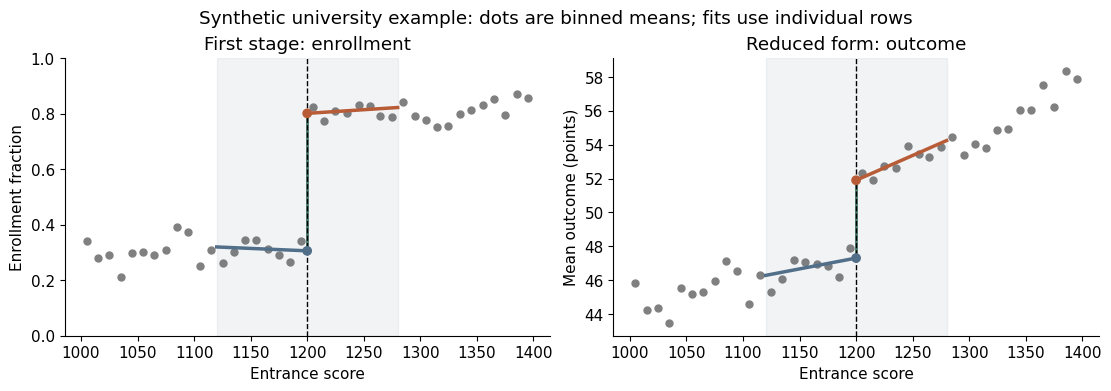

In [14]:
score_bins = np.linspace(1000, 1400, 41)  # 1200 is a bin edge
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for ax, outcome, result, title in [
    (axes[0], "S", first_stage, "First stage: enrollment"),
    (axes[1], "Y", reduced_form, "Reduced form: outcome"),
]:
    means = binned_means(university, "score", outcome, score_bins)
    ax.scatter(means["r"], means["y"], color="0.5", s=25)
    ax.axvspan(1200 - fuzzy_h, 1200 + fuzzy_h, color=BLUE, alpha=0.08)
    draw_rd_lines(ax, result)
    ax.set(xlabel="Entrance score", title=title)
axes[0].set(ylabel="Enrollment fraction", ylim=(0, 1))
axes[1].set(ylabel="Mean outcome (points)")
fig.suptitle("Synthetic university example: dots are binned means; fits use individual rows")
plt.show()

## 6. Exercise
For each claim, give one correction.

1. “RDD estimates the ATE for everyone in the bandwidth.”
2. “A smooth histogram proves that the design is valid.”
3. “The mortality jump is the causal effect of alcohol consumption.”

<details><summary>Answers</summary>
<ol>
<li>Sharp RDD targets the effect at the cutoff; fuzzy RDD targets the effect for compliers at the cutoff. The bandwidth is an estimation choice, not the definition of the causal population.</li>
<li>Density and baseline-covariate checks can reveal problems but cannot prove continuity of potential outcomes, rule out all sorting, or exclude another policy at the cutoff.</li>
<li>Our sharp analysis concerns legal access at age 21. A consumption effect requires consumption data, a first stage, and additional IV assumptions.</li>
</ol>
</details>
